# Pixel embedding resource analysis

Parse every request recorded in `pixellogs/*.txt` and compare the three embedding inputs: **image**, **text** (logged as JSON only), and **image+text** (logged as Image + JSON).

The analysis treats a request as usable when its response time, energy, and average-power result lines are all present. This retains completed requests from a partially written log while excluding request sections that stopped before producing results. Missing memory fields remain `NaN`, so older logs still contribute to time and power statistics.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

LOG_DIR = Path("pixellogs")
EMBEDDING_ORDER = ["image", "text", "image+text"]
LABEL_TO_TYPE = {
    "Image only": "image",
    "JSON only": "text",
    "Image + JSON": "image+text",
}


## Parser

Parsing is request-section based instead of reading the final summary, because the detailed sections contain the newer RSS fields and can preserve a completed request from an otherwise interrupted log. `VmHWM` is the process-lifetime resident-set high-water mark; the log labels make clear that it includes model startup as well as the request.

In [2]:
NUMBER = r"([-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?)"
REQUEST_RE = re.compile(
    r"^=== Request\s+\d+/\d+:\s*(.*?)\s*===\s*$",
    re.MULTILINE,
)

# Patterns are deliberately tied to units so that the two Energy consumption
# lines (mWh and J) cannot be confused with one another.
NUMERIC_FIELDS = {
    "embedding_dimensions": rf"^\[RESULT\] Embedding dimensions:\s*{NUMBER}\s*$",
    "response_time_s": rf"^\[RESULT\] Response time:\s*{NUMBER}\s*seconds\s*$",
    "charge_used_uah": rf"^\[RESULT\] Battery charge used:\s*{NUMBER}\s*microamp-hours\s*$",
    "mean_voltage_v": rf"^\[RESULT\] Mean battery voltage:\s*{NUMBER}\s*V\s*$",
    "energy_mwh": rf"^\[RESULT\] Energy consumption:\s*{NUMBER}\s*mWh\s*$",
    "energy_j": rf"^\[RESULT\] Energy consumption:\s*{NUMBER}\s*J\s*$",
    "average_power_w": rf"^\[RESULT\] Average power:\s*{NUMBER}\s*W\s*$",
    "current_before_ma": rf"^\[RESULT\] Battery current before:\s*{NUMBER}\s*mA\s*$",
    "current_after_ma": rf"^\[RESULT\] Battery current after:\s*{NUMBER}\s*mA\s*$",
    "rss_before_mib": rf"^\[RESULT\] Process RSS before request:\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
    "rss_after_mib": rf"^\[RESULT\] Process RSS after request:\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
    "peak_rss_mib": rf"^\[RESULT\] Process peak RSS \(startup \+ request, VmHWM\):\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
}
NUMERIC_FIELDS = {
    name: re.compile(pattern, re.MULTILINE)
    for name, pattern in NUMERIC_FIELDS.items()
}
METHOD_RE = re.compile(
    r"^\[RESULT\] Measurement method:\s*(.+?)\s*$", re.MULTILINE
)
RUN_ID_RE = re.compile(r"^Run ID:\s*(\d+)\s*$", re.MULTILINE)
STARTED_RE = re.compile(r"^Started:\s*(.+?)\s*$", re.MULTILINE)
EXIT_RE = re.compile(r"^Exit code:\s*(-?\d+)\s*$", re.MULTILINE)


def _numeric_value(pattern, section):
    match = pattern.search(section)
    return float(match.group(1)) if match else np.nan


def read_log_text(path):
    """Decode PowerShell UTF-16 logs and ordinary UTF-8 logs."""
    raw = path.read_bytes()
    if raw.startswith((b"\xff\xfe", b"\xfe\xff")):
        return raw.decode("utf-16", errors="replace")
    return raw.decode("utf-8-sig", errors="replace")


def parse_pixel_log(path):
    """Return (request rows, log metadata) parsed from one Pixel log."""
    text = read_log_text(path)
    run_match = RUN_ID_RE.search(text)
    run_id = int(run_match.group(1)) if run_match else (
        int(path.stem) if path.stem.isdigit() else path.stem
    )
    started_match = STARTED_RE.search(text)
    exit_match = EXIT_RE.search(text)
    headings = list(REQUEST_RE.finditer(text))

    metadata = {
        "run_id": run_id,
        "log_file": path.name,
        "started": started_match.group(1) if started_match else None,
        "exit_code": int(exit_match.group(1)) if exit_match else pd.NA,
        "has_summary": "=== Summary ===" in text,
        "request_sections": len(headings),
    }

    rows = []
    for index, heading in enumerate(headings):
        end = headings[index + 1].start() if index + 1 < len(headings) else len(text)
        section = text[heading.end():end]
        raw_label = heading.group(1).strip()
        row = {
            "run_id": run_id,
            "log_file": path.name,
            "request_number": index + 1,
            "request_label": raw_label,
            "embedding_type": LABEL_TO_TYPE.get(raw_label, raw_label.lower()),
            "log_has_summary": metadata["has_summary"],
            "log_exit_code": metadata["exit_code"],
        }
        row.update({
            name: _numeric_value(pattern, section)
            for name, pattern in NUMERIC_FIELDS.items()
        })
        method_match = METHOD_RE.search(section)
        row["measurement_method"] = (
            method_match.group(1).strip() if method_match else None
        )
        required = ("response_time_s", "energy_mwh", "average_power_w")
        row["request_complete"] = all(pd.notna(row[field]) for field in required)
        row["rss_delta_mib"] = (
            row["rss_after_mib"] - row["rss_before_mib"]
            if pd.notna(row["rss_after_mib"]) and pd.notna(row["rss_before_mib"])
            else np.nan
        )
        rows.append(row)

    metadata["complete_requests"] = sum(row["request_complete"] for row in rows)
    return rows, metadata


In [3]:
if not LOG_DIR.is_dir():
    raise FileNotFoundError(f"Pixel log directory not found: {LOG_DIR.resolve()}")

def log_sort_key(path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.name)

request_rows = []
log_rows = []
for log_path in sorted(LOG_DIR.glob("*.txt"), key=log_sort_key):
    rows, metadata = parse_pixel_log(log_path)
    request_rows.extend(rows)
    log_rows.append(metadata)

all_requests = pd.DataFrame(request_rows)
logs = pd.DataFrame(log_rows)
measurements = all_requests.loc[all_requests["request_complete"]].copy()
measurements["embedding_type"] = pd.Categorical(
    measurements["embedding_type"], categories=EMBEDDING_ORDER, ordered=True
)
measurements = measurements.sort_values(["run_id", "embedding_type"]).reset_index(drop=True)

print(f"Log files: {len(logs):,}")
print(f"Request sections: {len(all_requests):,}")
print(f"Usable completed requests: {len(measurements):,}")
print(f"Incomplete request sections excluded: {(~all_requests['request_complete']).sum():,}")


Log files: 150
Request sections: 440
Usable completed requests: 439
Incomplete request sections excluded: 1


## Data-quality and coverage audit

Counts are shown separately for each metric because memory was added later. A run need not have a successful wrapper exit line for an individual request to be usable: the parser relies on the presence of all three core `[RESULT]` values.

In [4]:
coverage = (
    measurements.groupby("embedding_type", observed=False)
    .agg(
        requests=("run_id", "size"),
        time_n=("response_time_s", "count"),
        energy_n=("energy_mwh", "count"),
        power_n=("average_power_w", "count"),
        rss_before_n=("rss_before_mib", "count"),
        rss_after_n=("rss_after_mib", "count"),
        peak_rss_n=("peak_rss_mib", "count"),
    )
)
display(coverage)

incomplete = all_requests.loc[
    ~all_requests["request_complete"],
    ["run_id", "log_file", "request_number", "embedding_type",
     "response_time_s", "energy_mwh", "average_power_w"],
]
if not incomplete.empty:
    print("Incomplete request sections (excluded from analysis):")
    display(incomplete)

no_request_logs = logs.loc[logs["request_sections"] == 0]
if not no_request_logs.empty:
    print("Logs with no request section (for example, skipped inputs):")
    display(no_request_logs[["run_id", "log_file", "has_summary", "exit_code"]])


,requests,time_n,energy_n,power_n,rss_before_n,rss_after_n,peak_rss_n
embedding_type,,,,,,,
image,147,147,147,147,2,2,2
text,146,146,146,146,1,1,1
image+text,146,146,146,146,1,1,1


Incomplete request sections (excluded from analysis):


,run_id,log_file,request_number,embedding_type,response_time_s,energy_mwh,average_power_w
436,150,150.txt,2,image+text,NaN,NaN,NaN


Logs with no request section (for example, skipped inputs):


,run_id,log_file,has_summary,exit_code
89,90,90.txt,False,<NA>
90,91,91.txt,False,<NA>
92,93,93.txt,False,<NA>


## Descriptive statistics

Energy (`mWh` or `J`) answers how much battery energy one embedding consumed. Average power (`W`) is energy divided by response time and answers the rate of draw during that request. Both are reported because a slower request can consume more total energy even at lower average wattage.

In [5]:
STAT_COLUMNS = ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]

def descriptive_table(frame, metrics):
    """Tidy groupwise describe() output for {column: display label}."""
    tables = []
    for column, label in metrics.items():
        table = (
            frame.groupby("embedding_type", observed=False)[column]
            .describe(percentiles=[0.25, 0.5, 0.75])[STAT_COLUMNS]
            .reset_index()
        )
        table.insert(0, "metric", label)
        tables.append(table)
    return pd.concat(tables, ignore_index=True).set_index(["metric", "embedding_type"])

performance_metrics = {
    "response_time_s": "Response time (s)",
    "energy_mwh": "Energy (mWh / embedding)",
    "energy_j": "Energy (J / embedding)",
    "average_power_w": "Average power (W)",
}
performance_stats = descriptive_table(measurements, performance_metrics)
display(performance_stats.round(3))


count     mean      std      min      25%      50%      75%      max
metric                   embedding_type                                                                      
Response time (s)        image           147.0   67.353    4.825   51.124   64.411   66.184   69.641   80.859
                         text            146.0   25.384   28.936    0.884    8.028   14.052   30.472  148.600
                         image+text      146.0  107.073   38.460   59.808   81.326   94.043  117.638  256.831
Energy (mWh / embedding) image           147.0   75.495   10.539   60.720   68.445   74.140   78.430  133.904
                         text            146.0   31.965   30.356    0.000    7.999   22.590   40.715  148.580
                         image+text      146.0  110.519   34.348   74.300   87.288  101.255  120.696  240.219
Energy (J / embedding)   image           147.0  271.783   37.940  218.592  246.402  266.904  282.348  482.054
                         text            146.0  115.076  109.281    0.000   28.796   81.324  146.574  534.888
                         image+text      146.0  397.869  123.651  267.480  314.237  364.518  434.504  864.788
Average power (W)        image           147.0    4.063    0.756    3.059    3.710    3.955    4.145    8.427
                         text            146.0    5.278    3.407    0.000    4.067    4.822    5.874   32.809
                         image+text      146.0    3.790    0.560    3.070    3.503    3.708    3.910    8.020

In [6]:
memory_metrics = {
    "rss_before_mib": "RSS before request (MiB)",
    "rss_after_mib": "RSS after request (MiB)",
    "peak_rss_mib": "Peak RSS: startup + request (MiB)",
    "rss_delta_mib": "RSS increase during request (MiB)",
}
memory_stats = descriptive_table(measurements, memory_metrics)
display(memory_stats.round(3))

memory_rows = measurements.loc[
    measurements["peak_rss_mib"].notna(),
    ["run_id", "embedding_type", "rss_before_mib", "rss_after_mib",
     "peak_rss_mib", "rss_delta_mib"],
]
print("Individual requests with memory measurements:")
display(memory_rows.round(3))


count      mean    std       min       25%       50%       75%       max
metric                            embedding_type                                                                          
RSS before request (MiB)          image             2.0  3383.306  0.008  3383.301  3383.304  3383.306  3383.309  3383.312
                                  text              1.0  3383.570    NaN  3383.570  3383.570  3383.570  3383.570  3383.570
                                  image+text        1.0  3383.438    NaN  3383.438  3383.438  3383.438  3383.438  3383.438
RSS after request (MiB)           image             2.0  4228.272  0.152  4228.164  4228.218  4228.272  4228.325  4228.379
                                  text              1.0  3989.500    NaN  3989.500  3989.500  3989.500  3989.500  3989.500
                                  image+text        1.0  4266.430    NaN  4266.430  4266.430  4266.430  4266.430  4266.430
Peak RSS: startup + request (MiB) image             2.0  4244.015  0.431  4243.711  4243.863  4244.015  4244.168  4244.320
                                  text              1.0  3989.504    NaN  3989.504  3989.504  3989.504  3989.504  3989.504
                                  image+text        1.0  4267.062    NaN  4267.062  4267.062  4267.062  4267.062  4267.062
RSS increase during request (MiB) image             2.0   844.965  0.160   844.852   844.908   844.965   845.022   845.078
                                  text              1.0   605.930    NaN   605.930   605.930   605.930   605.930   605.930
                                  image+text        1.0   882.992    NaN   882.992   882.992   882.992   882.992   882.992

Individual requests with memory measurements:


,run_id,embedding_type,rss_before_mib,rss_after_mib,peak_rss_mib,rss_delta_mib
435,150,image,3383.301,4228.379,4244.320,845.078
436,151,image,3383.312,4228.164,4243.711,844.852
437,151,text,3383.570,3989.500,3989.504,605.930
438,151,image+text,3383.438,4266.430,4267.062,882.992


## Boxplots

Each box uses the available values for that metric; the tick labels give the actual sample size. Points are overlaid so that the very small memory sample in the latest logs is not visually overstated by a box. The diamond marks the mean.

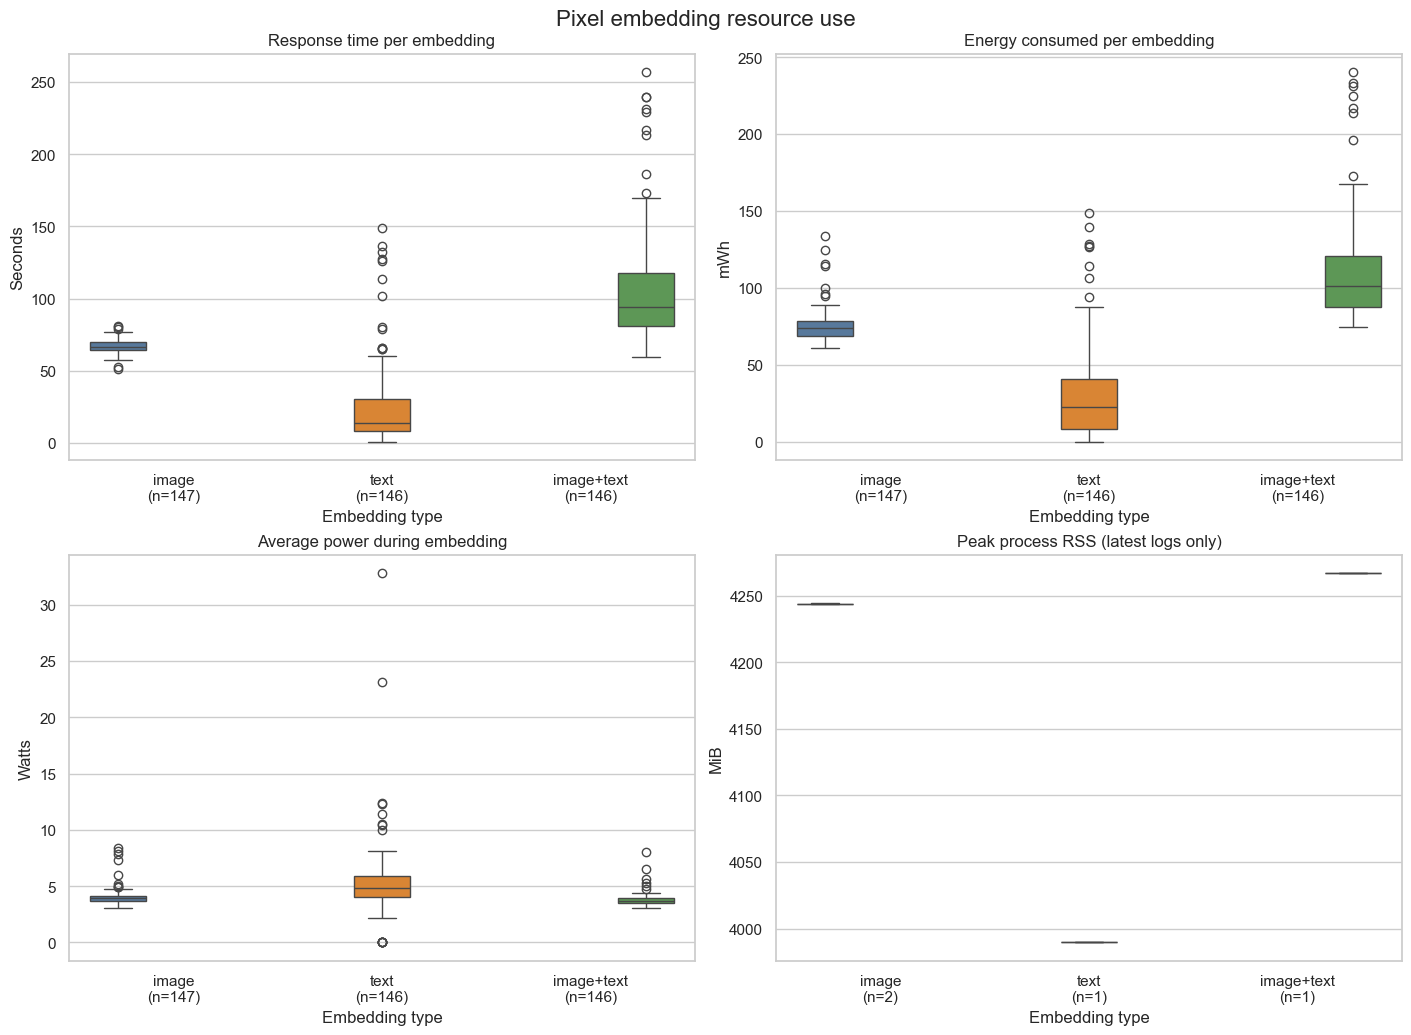

In [7]:
plot_specs = [
    ("response_time_s", "Response time per embedding", "Seconds"),
    ("energy_mwh", "Energy consumed per embedding", "mWh"),
    ("average_power_w", "Average power during embedding", "Watts"),
    ("peak_rss_mib", "Peak process RSS", "MiB"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
palette = ["#4C78A8", "#F58518", "#54A24B"]
for ax, (column, title, ylabel) in zip(axes.flat, plot_specs):
    available = measurements.loc[measurements[column].notna()]
    sns.boxplot(
        data=available, x="embedding_type", y=column, order=EMBEDDING_ORDER,
        hue="embedding_type", palette=palette, legend=False, showmeans=False,
        meanprops={"marker": "D", "markerfacecolor": "white",
                   "markeredgecolor": "black", "markersize": 5},
        ax=ax,
    )
    #sns.stripplot(
    #    data=available, x="embedding_type", y=column, order=EMBEDDING_ORDER,
    #    color="black", alpha=0.35, size=3, jitter=0.18, ax=ax,
    #)
    counts = available.groupby("embedding_type", observed=False)[column].count()
    ax.set_xticks(range(len(EMBEDDING_ORDER)))
    ax.set_xticklabels([f"{kind}\n(n={int(counts.get(kind, 0))})" for kind in EMBEDDING_ORDER])
    ax.set_title(title)
    ax.set_xlabel("Embedding type")
    ax.set_ylabel(ylabel)

fig.suptitle("Pixel embedding resource use", fontsize=16, y=1.02)
plt.show()


## Compact comparison and interpretation notes

In [8]:
comparison = (
    measurements.groupby("embedding_type", observed=False)
    .agg(
        n=("run_id", "size"),
        median_time_s=("response_time_s", "median"),
        median_energy_mwh=("energy_mwh", "median"),
        median_power_w=("average_power_w", "median"),
        memory_n=("peak_rss_mib", "count"),
        median_peak_rss_mib=("peak_rss_mib", "median"),
        median_rss_delta_mib=("rss_delta_mib", "median"),
    )
)
display(comparison.round(3))


,n,median_time_s,median_energy_mwh,median_power_w,memory_n,median_peak_rss_mib,median_rss_delta_mib
embedding_type,,,,,,,
image,147,66.184,74.140,3.955,2,4244.015,844.965
text,146,14.052,22.590,4.822,1,3989.504,605.930
image+text,146,94.043,101.255,3.708,1,4267.062,882.992


### Measurement cautions

- Battery energy comes from Android's counter (or, in these logs, charge-counter delta multiplied by mean voltage). Its finite resolution can make short requests especially noisy.
- Average power is calculated as measured energy divided by HTTP response time. It is whole-phone draw over that window, not an isolated accelerator/model rail measurement.
- `VmRSS`/`VmHWM` are kernel process-RSS estimates, not PSS or device-wide memory. `VmHWM` includes server/model startup plus the request, while `RSS after - RSS before` estimates the request-time resident increase.
- Memory boxplots and statistics use only logs where the fields exist. Always read `memory_n`; with one or two observations per type, those values are descriptive examples rather than stable distribution estimates.
- Input screens differ in image and cleaned-JSON complexity. These plots summarize the observed workload; they do not control for input token count or image complexity.